In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# ---Prepare data---
# The frame is just the same as DESeq2 output
# You can replace the part with the date treated by DESeq2 in week03
np.random.seed(2004)
n = 2000

df = pd.DataFrame({
    "gene": [f"gene{i}" for i in range(n)],  #列表推导式 List comprehension
    "log2FoldChange": np.concatenate([
        np.random.normal(0, 0.5, 1700),  #Most genes are not significant
        np.random.normal(3, 0.8, 150),   #Up regulated genes
        np.random.normal(-3, 0.8, 150)   #Down regulated genes
    ]),
    "padj": np.concatenate([
        np.random.uniform(0.1, 1, 1700),  #Not significant
        np.random.uniform(0, 0.05, 300)  #Significant
    ])
})

# Remove the rows padj = NaN
df = df.dropna(subset=["padj"])

# Calculate Y-axis: -log10(padj)
# clip(lower = 1e-300): replace 0 with minimal value, avoiding log10(0)=-∞
df["neg_log10_padj"] = -np.log10(df["padj"].clip(lower=1e-300))

print("Data view:")
display(df.head())
print(f"\nTotal genes: {len(df)}")
print(f"log2FC range: {df['log2FoldChange'].min():.2f} to {df['log2FoldChange'].max():.2f}")
print(f"-log10(padj) range: {df['neg_log10_padj'].min():.2f} to {df['neg_log10_padj'].max():.2f}")

Data view:


,gene,log2FoldChange,padj,neg_log10_padj
0,gene0,0.649030,0.904551,0.043567
1,gene1,0.187070,0.319719,0.495231
2,gene2,-0.716343,0.376473,0.424266
3,gene3,-1.485590,0.673735,0.171511
4,gene4,0.372874,0.348424,0.457892



Total genes: 2000
log2FC range: -4.69 to 5.81
-log10(padj) range: 0.00 to 5.68


In [2]:
# ---Define significance threshold---
FC_THRESHOLD = 1           # log2FC threshold (i.e., 2-fold change)
PADJ_THRESHOLD = 0.5       # FDR threshold

# ---Classify each gene---
def classify_gene(row):
    """
    Classify each gene based on log2FC and padj.

    Parameters:
        row: one row of DataFrame containing log2FoldChange and padj

    Returns:
        str: gene category
            'Up'   - significantly upregulated
            'Down' - significantly downregulated
            'Sig'  - significant but small fold change
            'NS'   - not significant
    """
    sig = row["padj"] < PADJ_THRESHOLD
    up = row["log2FoldChange"] > FC_THRESHOLD
    down = row["log2FoldChange"] < FC_THRESHOLD

    if sig and up:
        return "Up"
    elif sig and down:
        return "Down"
    elif sig:
        return "Sig"
    else:
        return "NS"

df["category"] = df.apply(classify_gene, axis=1)

#Calculate the number of each gene
counts = df["category"].value_counts()
print(counts)


category
NS      921
Down    909
Up      170
Name: count, dtype: int64


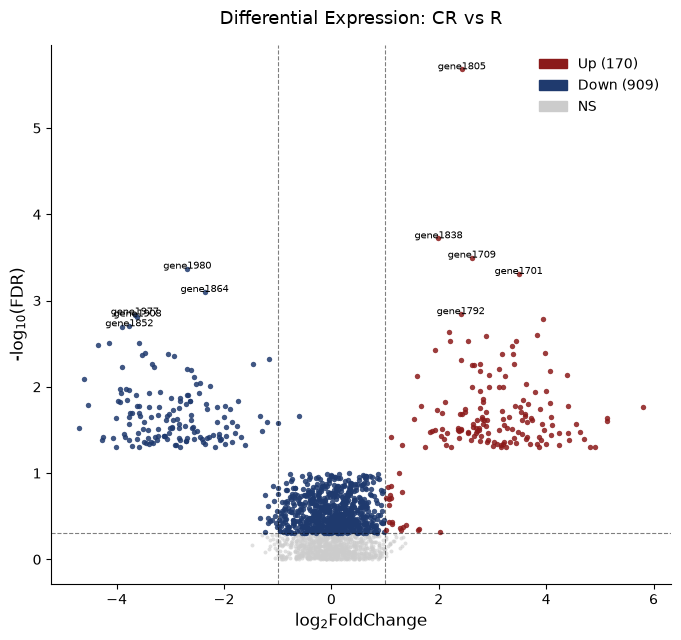

In [8]:
# ---Plot---
# ---Define colors---
colors = {
    "Up": "#8B1A1A",
    "Down": "#1F3A6E",
    "Sig": "#A8C8E8",
    "NS": "#CCCCCC",
}

fig, ax = plt.subplots(figsize=(8, 7))

# ---Create a scatter plot---
# Draw NS firstly, then Sig
# Ensure significant points are not obscured by gray points
for category in ['NS', 'Sig', 'Down', 'Up']:
    mask = df["category"] == category
    ax.scatter(
        df.loc[mask, "log2FoldChange"],
        df.loc[mask, "neg_log10_padj"],
        c=colors[category],
        s=8 if category == 'NS' else 15,
        alpha=0.6 if category == 'NS' else 0.85,
        linewidths=0,
        label=category
    )

# ---Add threshold line---
ax.axhline(y=-np.log10(PADJ_THRESHOLD),
           linestyle='--',
           color='black',
           linewidth=0.8,
           alpha=0.5)
ax.axvline(x=FC_THRESHOLD,
           linestyle='--',
           color='black',
           linewidth=0.8,
           alpha=0.5)
ax.axvline(x=-FC_THRESHOLD,
           linestyle='--',
           color='black',
           linewidth=0.8,
           alpha=0.5)

# ---Mark the most 5 significant up- and down- regulated genes---
top_up = df[df["category"] == "Up"].nlargest(5, "neg_log10_padj")
top_down = df[df["category"] == "Down"].nlargest(5, "neg_log10_padj")

for _, row in pd.concat([top_up, top_down]).iterrows():
    ax.annotate(
        row["gene"],
        xy=(row["log2FoldChange"], row["neg_log10_padj"]),
        fontsize=7,
        ha='center',
        color='black'
    )

# ---Figure legnged---
up_count = counts.get("Up", 0)
down_count = counts.get("Down", 0)

legend_elements = [
    mpatches.Patch(color=colors["Up"],
                   label=f"Up ({up_count})"),
    mpatches.Patch(color=colors["Down"],
                   label=f"Down ({down_count})"),
    mpatches.Patch(color=colors["NS"],
                   label="NS")
]
ax.legend(handles=legend_elements,
          loc='upper right',
          frameon=False,
          fontsize=10)

# ---Axis and Title---
ax.set_xlabel(r"log$_2$FoldChange", fontsize=12)  #Latex writting style
ax.set_ylabel(r"-log$_{10}$(FDR)", fontsize=12)
ax.set_title("Differential Expression: CR vs R", fontsize=13, pad=15)

# Nature style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_color("black")
ax.spines["left"].set_color("black")

# Transparent background
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.rcParams["text.color"]      = "black"
plt.rcParams["axes.labelcolor"] = "black"
plt.rcParams["xtick.color"] = "black"
plt.rcParams["ytick.color"] = "black"

plt.tight_layout
plt.savefig("./volcano_plot.png", dpi = 600,
            bbox_inches = "tight", transparent = True)
plt.show()